# 01 · Data acquisition, cleaning & EDA
**Dataset:** UCI Heart Disease — Cleveland subset (UCI id 45), 303 patients, 13 clinical features + diagnosis.

This notebook is a thin narrative layer: the logic lives in `src/heartrisk/data.py` (download + cleaning) and
`src/heartrisk/eda.py` (plots), so the same code is unit-tested and reused by CI.

In [1]:
import logging
import pandas as pd
from IPython.display import Image, display

from heartrisk import config
from heartrisk.data import build_clean_dataset, load_raw, missing_report
from heartrisk import eda

logging.basicConfig(level=logging.INFO)
pd.set_option("display.width", 140)

Matplotlib is building the font cache; this may take a moment.


## 1. Acquire
Downloads `processed.cleveland.data` from UCI into `data/raw/` (skipped if already present). Equivalent CLI: `python scripts/download_data.py`.

In [2]:
df = build_clean_dataset()
raw = load_raw()
raw.head()

INFO:heartrisk.data:Raw file already present at /home/s2025ae05220/workspace/2025ae05220MLOpsAssignment1/data/raw/processed.cleveland.data


INFO:heartrisk.data:Wrote /home/s2025ae05220/workspace/2025ae05220MLOpsAssignment1/data/processed/heart_clean.csv (303 rows, 14 cols)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Clean
Raw-file issues and how they are handled:

| Issue | Handling |
|---|---|
| No header row | Column names assigned from the UCI documentation |
| `?` placeholders in `ca` (4) and `thal` (2) | Parsed as NaN; **imputed inside the model pipeline** (fit on training folds only → no leakage) |
| Target `num` is 0–4 severity | Binarised: `target = 1` if `num > 0` (presence of disease) |
| Codes outside documented domain / zero BP or cholesterol | Converted to NaN (none found in Cleveland, but guarded for new data) |
| Duplicate rows | Dropped (none found) |

In [3]:
print("raw shape  :", raw.shape)
print("clean shape:", df.shape)
print("\nmissing values:\n", missing_report(df))
df.describe().T.round(2)

raw shape  : (303, 14)
clean shape: (303, 14)

missing values:
 ca      4
thal    2
dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0


In [4]:
eda.apply_style()
paths = eda.generate_all(df)
show = lambda name: display(Image(filename=str(config.FIGURES_DIR / f"{name}.png")))

## 3. Class balance
54% / 46% — mild imbalance. Accuracy remains meaningful, but we'll also track recall (missing a sick patient is the costlier error) and ROC-AUC, and use stratified CV.

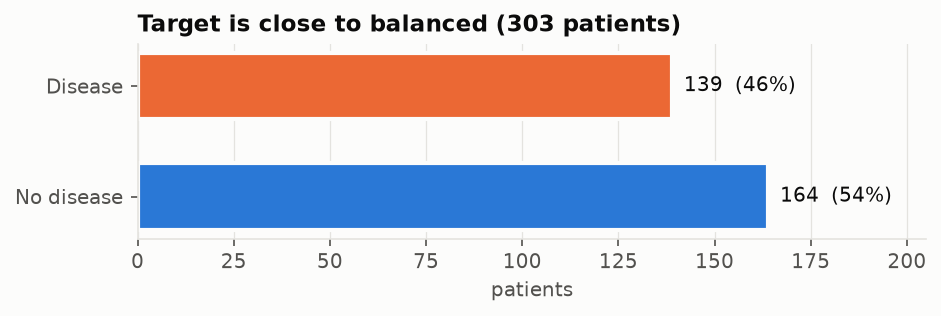

In [5]:
show("01_class_balance")

## 4. Numeric features
Outlined histograms per class make the overlap visible. `thalach` (max heart rate) shifts down and `oldpeak` (ST depression) shifts up for diseased patients; `chol` and `trestbps` barely separate. `ca` (vessels coloured by fluoroscopy) is a strong discrete signal.

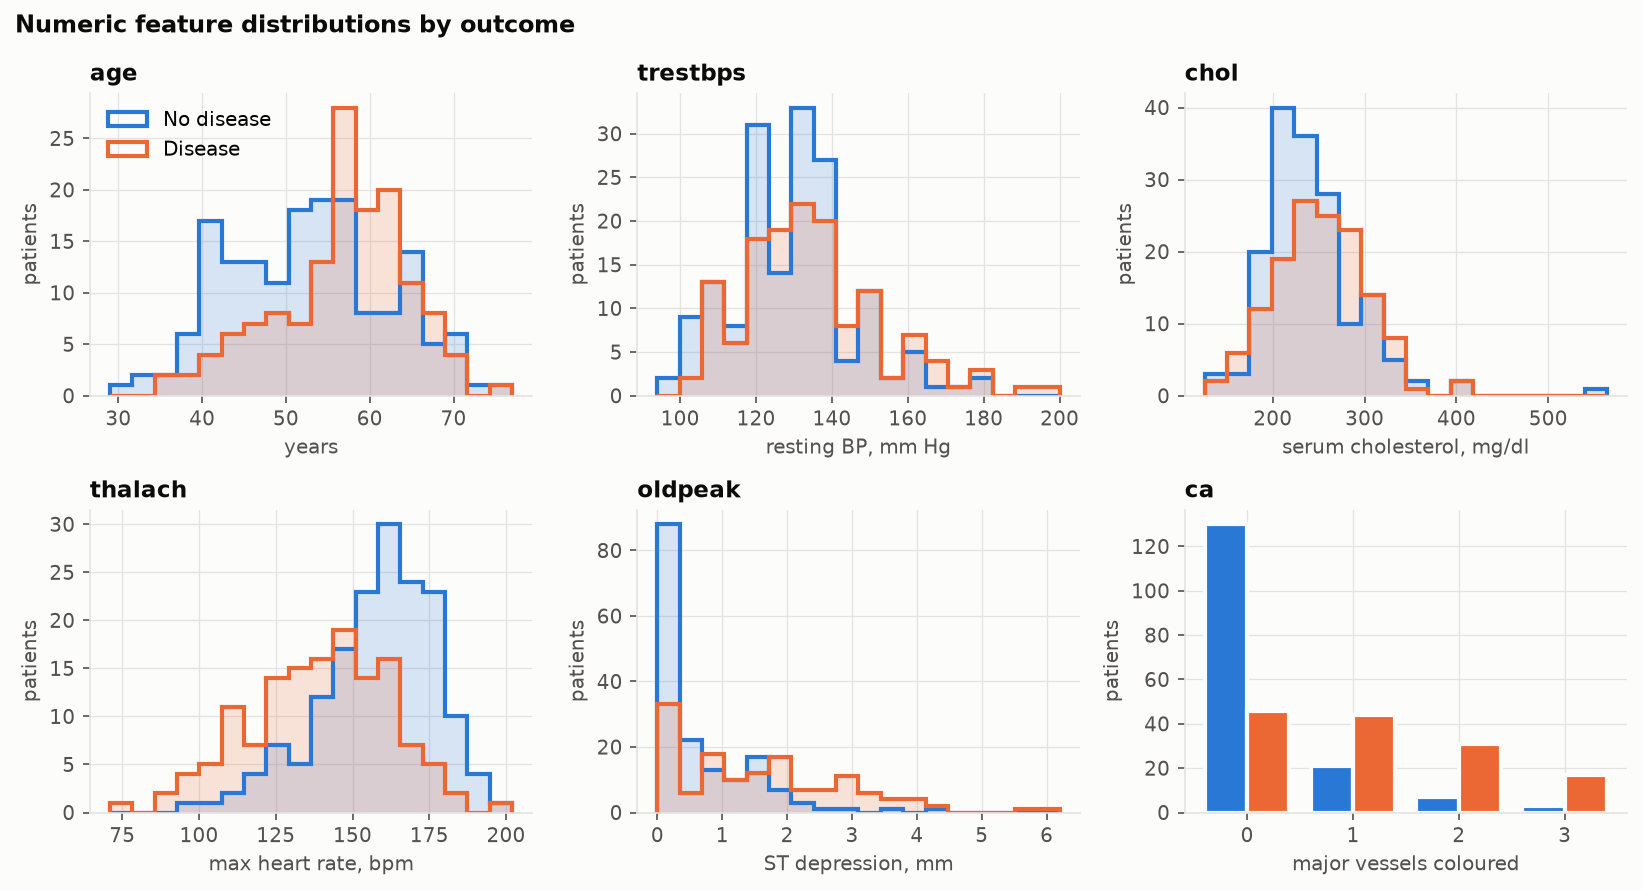

In [6]:
show("02_numeric_histograms")

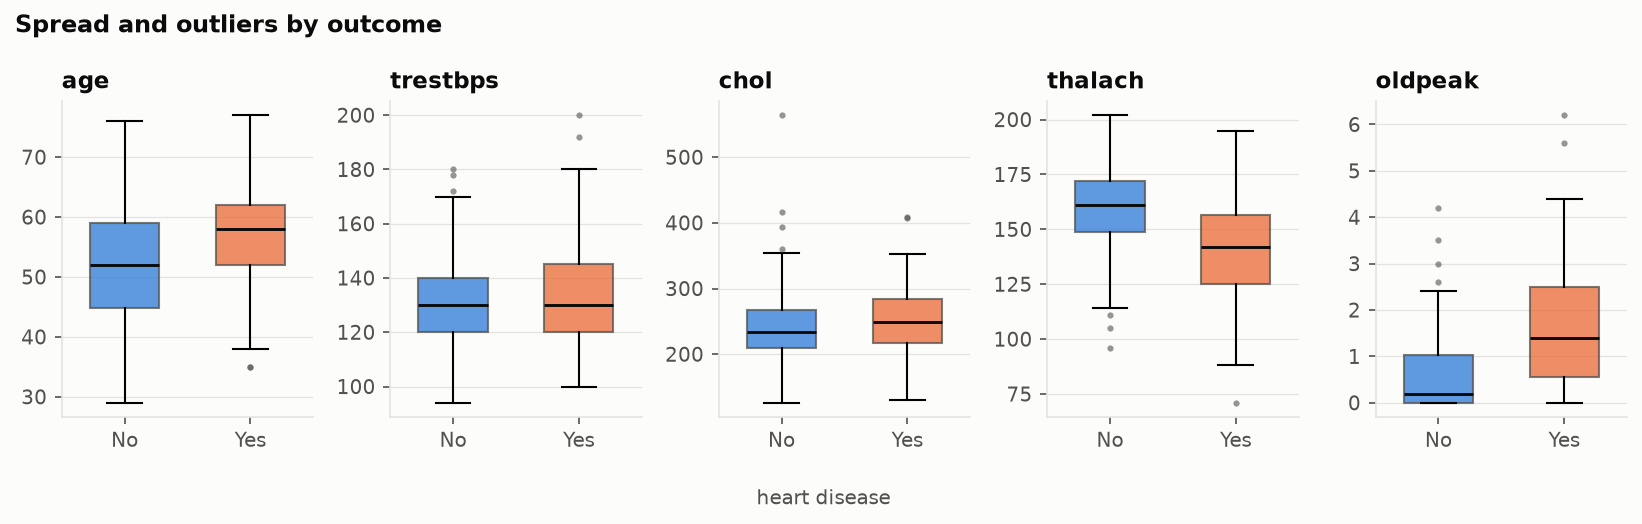

In [7]:
show("03_numeric_boxplots")

Outliers (e.g. `chol` = 564, `oldpeak` = 6.2) are clinically plausible, so they are **kept**; the scaler in the pipeline limits their effect on the linear model, and tree models are insensitive to them.

## 5. Categorical features — disease rate per category
Each bar is the share of patients in that category who have disease; the dashed line is the overall 46%. Asymptomatic chest pain (`cp=4`), exercise-induced angina, reversible `thal` defect and a flat ST slope all carry ~65–77% disease rates. `fbs` is nearly uninformative. `restecg=1` has only 4 patients, so its 75% is not reliable.

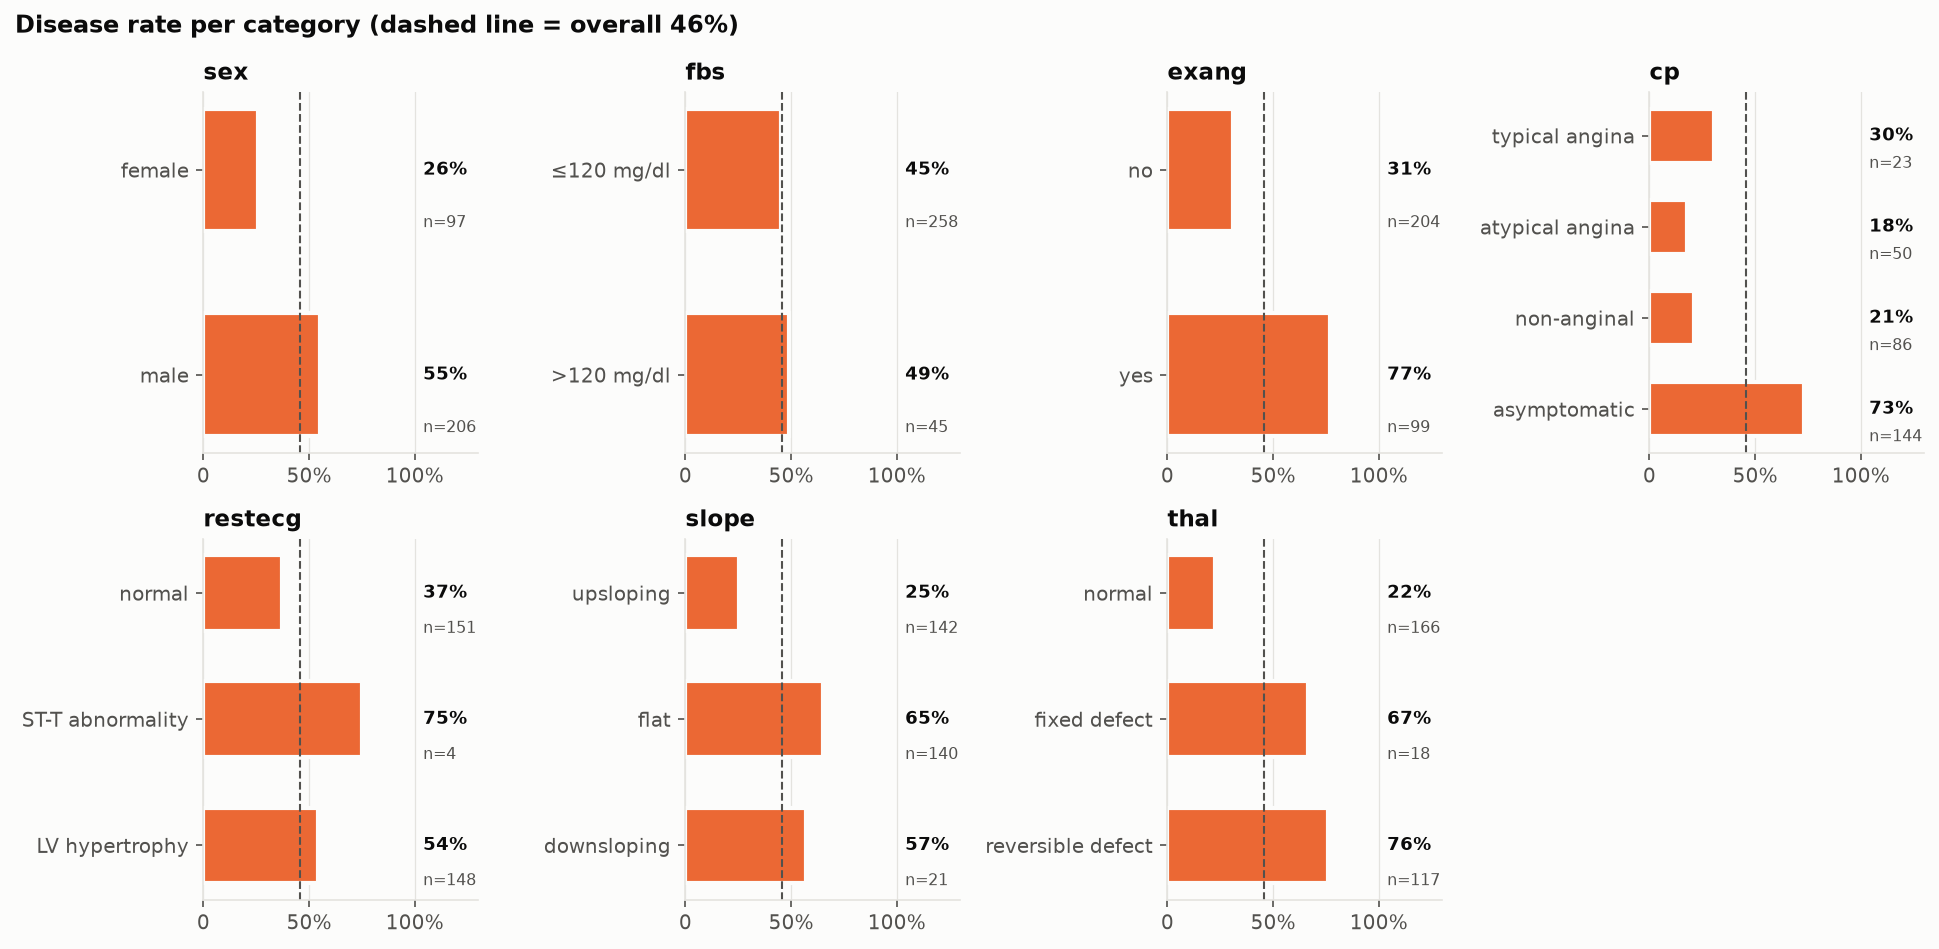

In [8]:
show("04_categorical_disease_rate")

## 6. Correlations
Spearman ρ is used because many columns are ordinal codes. Note `cp`, `restecg`, `thal` are *nominal*, so their ρ only indicates direction under the coding — they are one-hot encoded for modelling. No pair exceeds |ρ| = 0.6 (max: `oldpeak`–`slope` 0.59), so multicollinearity is not a concern.

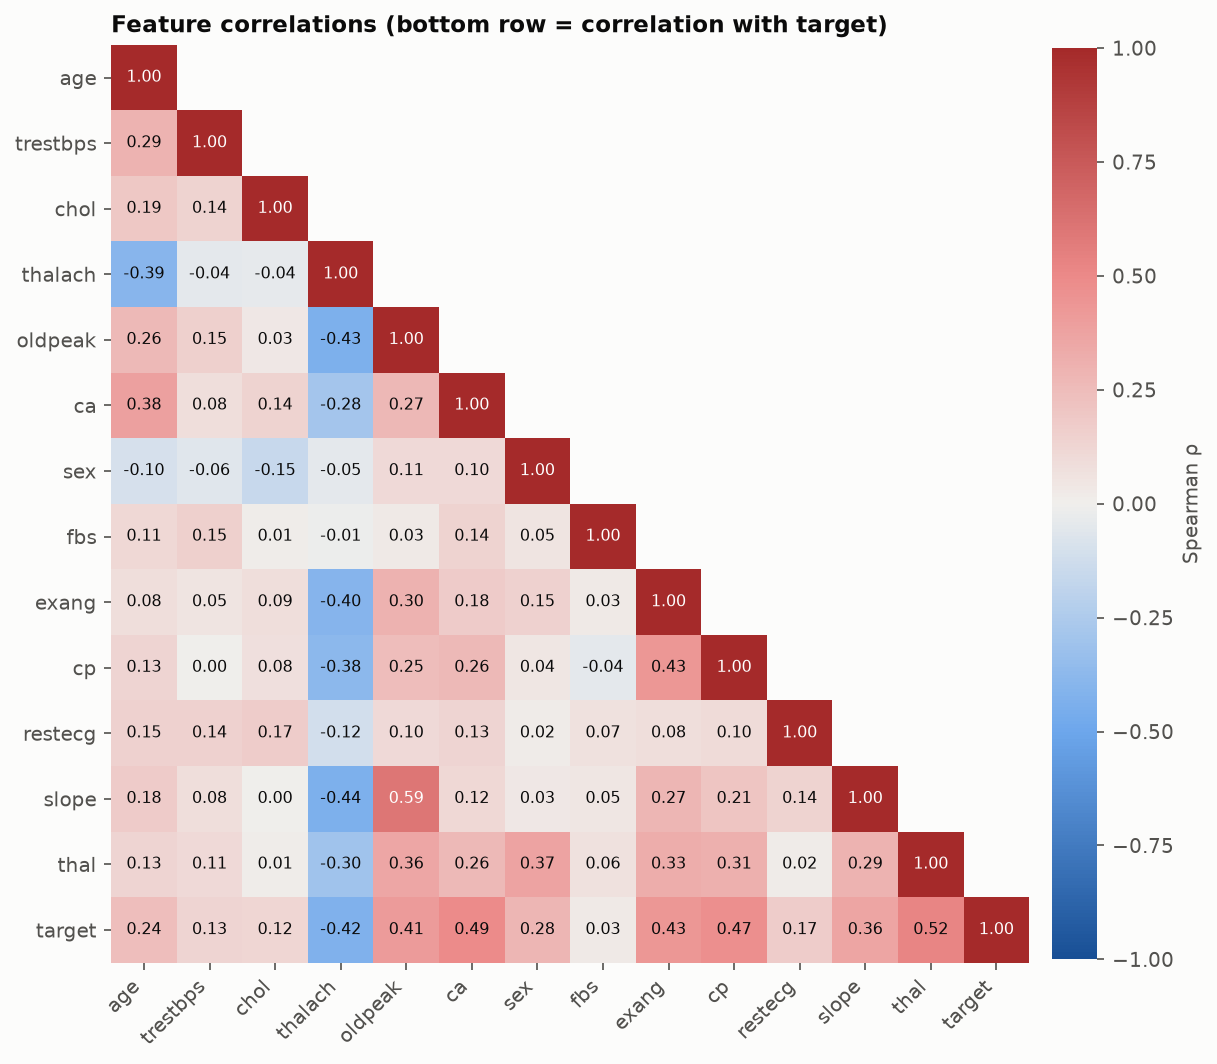

In [9]:
show("05_correlation_heatmap")

In [10]:
corr_target = df.corr(method="spearman")[config.TARGET].drop(config.TARGET)
corr_target.reindex(corr_target.abs().sort_values(ascending=False).index).round(3).to_frame("spearman_vs_target")

,spearman_vs_target
thal,0.522
ca,0.489
cp,0.472
exang,0.432
thalach,-0.423
oldpeak,0.413
slope,0.364
sex,0.277
age,0.237
restecg,0.169


## 7. Interaction: age × max heart rate
The dotted line is the age-predicted maximum (220 − age). Diseased patients cluster well below it at every age — a hint that a *heart-rate-reserve* style feature may help; we'll test it in feature engineering.

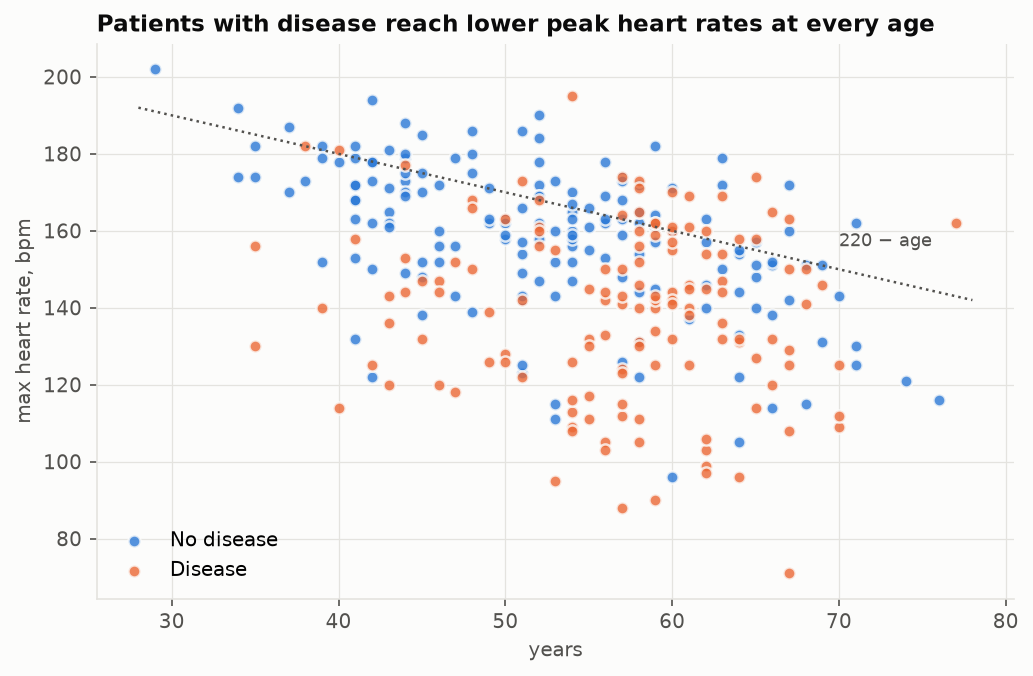

In [11]:
show("06_age_vs_thalach")

## 8. Takeaways for modelling
1. Small dataset (303 rows) → use **stratified k-fold CV** rather than a single split for model selection; keep a held-out test set for the final report.
2. Strongest signals: `thal`, `ca`, `cp`, `exang`, `oldpeak`, `thalach`. Weakest: `fbs`, `chol`.
3. Preprocessing: median-impute + scale numerics, most-frequent-impute + one-hot encode nominal categoricals (`cp`, `restecg`, `slope`, `thal`), pass binaries through.
4. Metrics: ROC-AUC as primary selection metric, with recall reported alongside accuracy/precision.